In [ ]:
# AI/ML-Based Predictive Maintenance and Vehicle Health Monitoring System

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Generate synthetic automotive sensor data

np.random.seed(42)

n_samples = 2000

data = pd.DataFrame({
    'engine_temperature': np.random.normal(85, 10, n_samples),
    'rpm': np.random.normal(2500, 500, n_samples),
    'oil_pressure': np.random.normal(40, 6, n_samples),
    'vibration': np.random.normal(1.5, 0.5, n_samples),
    'battery_voltage': np.random.normal(12.5, 0.5, n_samples),
    'coolant_temperature': np.random.normal(80, 8, n_samples),
    'fuel_consumption': np.random.normal(7, 1.5, n_samples),
    'vehicle_speed': np.random.normal(60, 15, n_samples),
    'operating_hours': np.random.uniform(100, 5000, n_samples)
})

# Display first five rows
data.head()

,engine_temperature,rpm,oil_pressure,vibration,battery_voltage,coolant_temperature,fuel_consumption,vehicle_speed,operating_hours
0,89.967142,2162.410863,34.819038,0.942959,12.483487,74.572042,8.762221,56.636386,2640.151135
1,83.617357,2427.740665,39.812779,1.184535,12.248175,77.556004,4.181529,56.837479,4566.590337
2,91.476885,2103.790040,40.108101,1.028970,12.413813,75.220952,6.508307,93.531412,1697.162565
3,100.230299,2346.019235,42.835782,1.226002,12.857366,80.883344,6.937510,72.139664,867.693458
4,82.658466,1553.192667,31.798850,1.392925,13.138928,89.577428,7.023863,97.209764,3572.788430


In [ ]:
# Keep sensor values within realistic ranges

data['engine_temperature'] = data['engine_temperature'].clip(60, 120)
data['rpm'] = data['rpm'].clip(800, 5000)
data['oil_pressure'] = data['oil_pressure'].clip(20, 60)
data['vibration'] = data['vibration'].clip(0.2, 4.0)
data['battery_voltage'] = data['battery_voltage'].clip(10.5, 14.5)
data['coolant_temperature'] = data['coolant_temperature'].clip(50, 110)
data['fuel_consumption'] = data['fuel_consumption'].clip(2, 15)
data['vehicle_speed'] = data['vehicle_speed'].clip(0, 140)
data['operating_hours'] = data['operating_hours'].clip(100, 5000)

data.head()

,engine_temperature,rpm,oil_pressure,vibration,battery_voltage,coolant_temperature,fuel_consumption,vehicle_speed,operating_hours
0,89.967142,2162.410863,34.819038,0.942959,12.483487,74.572042,8.762221,56.636386,2640.151135
1,83.617357,2427.740665,39.812779,1.184535,12.248175,77.556004,4.181529,56.837479,4566.590337
2,91.476885,2103.790040,40.108101,1.028970,12.413813,75.220952,6.508307,93.531412,1697.162565
3,100.230299,2346.019235,42.835782,1.226002,12.857366,80.883344,6.937510,72.139664,867.693458
4,82.658466,1553.192667,31.798850,1.392925,13.138928,89.577428,7.023863,97.209764,3572.788430


In [ ]:
# Calculate a risk score based on vehicle sensor conditions

risk_score = (
    (data['engine_temperature'] > 100).astype(int) +
    (data['vibration'] > 2.5).astype(int) +
    (data['oil_pressure'] < 30).astype(int) +
    (data['battery_voltage'] < 11.5).astype(int) +
    (data['coolant_temperature'] > 100).astype(int) +
    (data['operating_hours'] > 4000).astype(int)
)

# Convert risk score into failure probability
failure_probability = 1 / (1 + np.exp(-(risk_score - 2)))

# Generate failure labels
data['failure'] = (
    np.random.random(n_samples) < failure_probability
).astype(int)

data.head()

,engine_temperature,rpm,oil_pressure,vibration,battery_voltage,coolant_temperature,fuel_consumption,vehicle_speed,operating_hours,failure
0,89.967142,2162.410863,34.819038,0.942959,12.483487,74.572042,8.762221,56.636386,2640.151135,0
1,83.617357,2427.740665,39.812779,1.184535,12.248175,77.556004,4.181529,56.837479,4566.590337,1
2,91.476885,2103.790040,40.108101,1.028970,12.413813,75.220952,6.508307,93.531412,1697.162565,1
3,100.230299,2346.019235,42.835782,1.226002,12.857366,80.883344,6.937510,72.139664,867.693458,1
4,82.658466,1553.192667,31.798850,1.392925,13.138928,89.577428,7.023863,97.209764,3572.788430,0


In [ ]:
# Dataset information

print("Dataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nFailure Distribution:")
print(data['failure'].value_counts())

Dataset Shape: (2000, 10)

Column Names:
['engine_temperature', 'rpm', 'oil_pressure', 'vibration', 'battery_voltage', 'coolant_temperature', 'fuel_consumption', 'vehicle_speed', 'operating_hours', 'failure']

Missing Values:
engine_temperature     0
rpm                    0
oil_pressure           0
vibration              0
battery_voltage        0
coolant_temperature    0
fuel_consumption       0
vehicle_speed          0
operating_hours        0
failure                0
dtype: int64

Failure Distribution:
failure
0    1669
1     331
Name: count, dtype: int64


In [ ]:
# Statistical summary of the dataset

data.describe()

,engine_temperature,rpm,oil_pressure,vibration,battery_voltage,coolant_temperature,fuel_consumption,vehicle_speed,operating_hours,failure
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,85.466909,2496.778749,39.711966,1.498865,12.501577,79.795590,7.054525,60.179567,2608.683140,0.165500
std,9.828355,502.677026,5.997981,0.513567,0.494274,7.941396,1.499807,15.227405,1429.438235,0.371724
min,60.000000,990.243922,20.939777,0.200000,10.538800,52.995367,2.376157,5.471997,100.235807,0.000000
25%,78.773381,2145.437016,35.879260,1.137334,12.180157,74.591532,6.045437,49.982667,1408.773065,0.000000
50%,85.446917,2499.973348,39.818740,1.484738,12.507099,79.679032,7.077201,59.983175,2658.117398,0.000000
75%,91.829776,2832.771840,43.772910,1.855187,12.831263,84.989051,8.052118,70.440630,3847.723877,0.000000
max,120.000000,4463.118853,58.677461,3.264528,14.188691,107.022146,12.143366,127.186264,4999.514787,1.000000


In [ ]:
# Check for duplicate records

duplicates = data.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 0


In [ ]:
# Check data types of all columns

data.dtypes

,0
engine_temperature,float64
rpm,float64
oil_pressure,float64
vibration,float64
battery_voltage,float64
coolant_temperature,float64
fuel_consumption,float64
vehicle_speed,float64
operating_hours,float64
failure,int64


In [ ]:
# Count normal and failure cases

failure_counts = data['failure'].value_counts()

print("Normal vehicles:", failure_counts.get(0, 0))
print("Failure cases:", failure_counts.get(1, 0))

Normal vehicles: 1669
Failure cases: 331


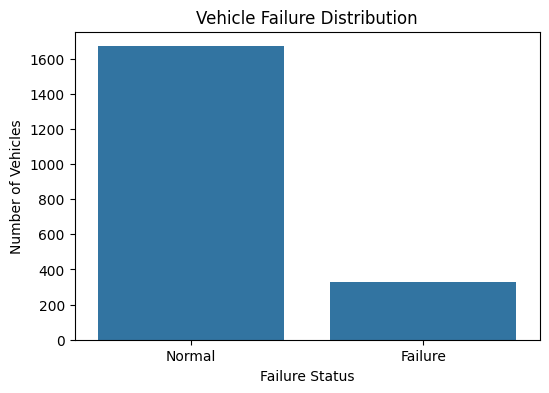

In [ ]:
# Visualize failure distribution

plt.figure(figsize=(6, 4))

sns.countplot(x='failure', data=data)

plt.title('Vehicle Failure Distribution')
plt.xlabel('Failure Status')
plt.ylabel('Number of Vehicles')
plt.xticks([0, 1], ['Normal', 'Failure'])

plt.show()

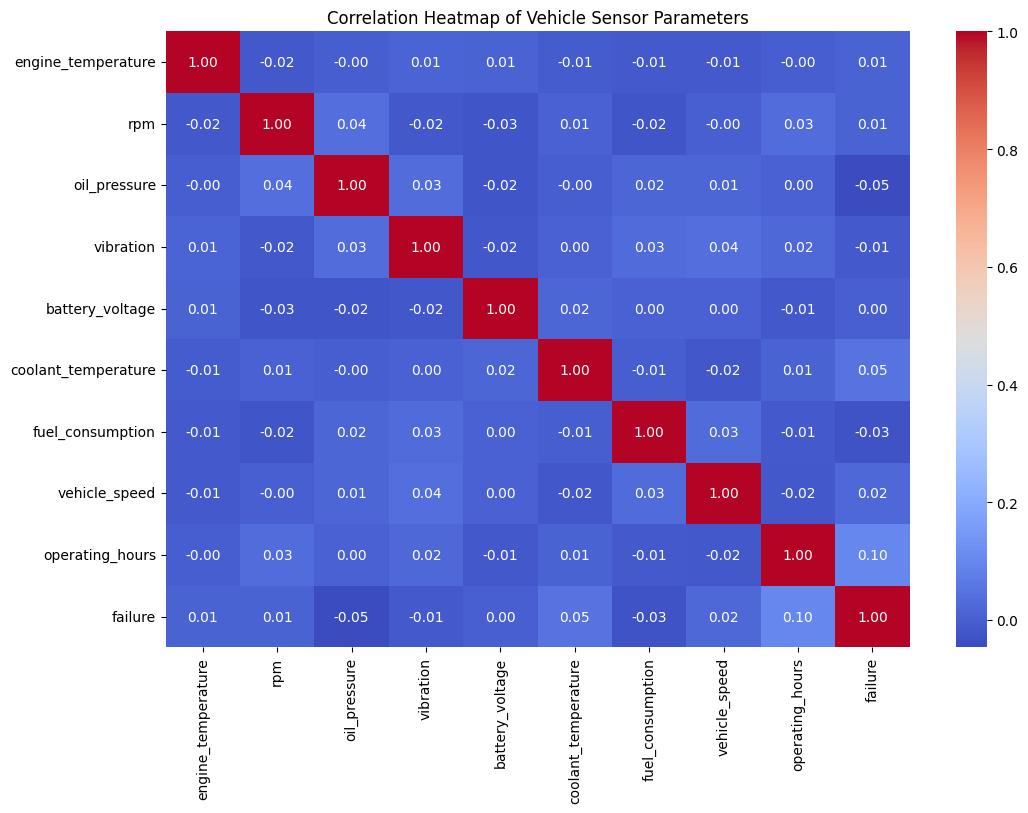

In [ ]:
# Correlation between vehicle sensor parameters

plt.figure(figsize=(12, 8))

sns.heatmap(
    data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Vehicle Sensor Parameters')

plt.show()

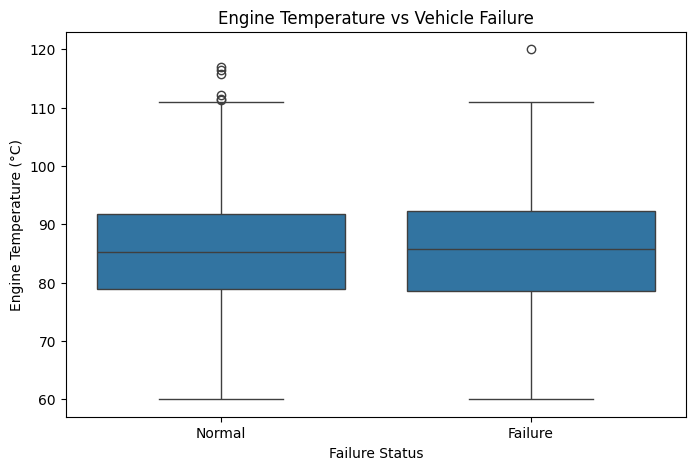

In [ ]:
# Engine temperature distribution by failure status

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='failure',
    y='engine_temperature',
    data=data
)

plt.title('Engine Temperature vs Vehicle Failure')
plt.xlabel('Failure Status')
plt.ylabel('Engine Temperature (°C)')
plt.xticks([0, 1], ['Normal', 'Failure'])

plt.show()

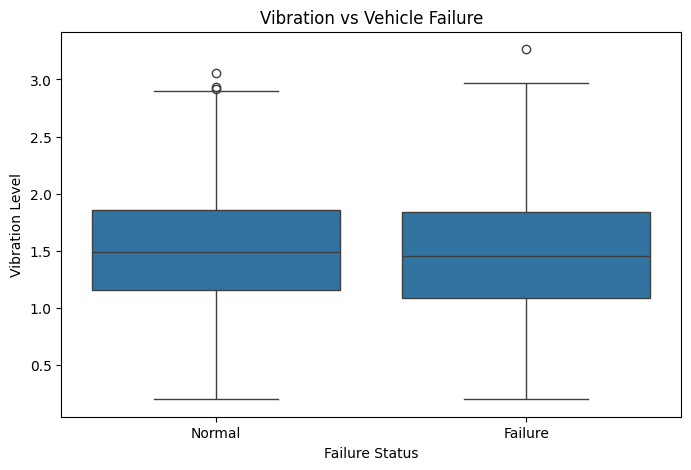

In [ ]:
# Vibration distribution by failure status

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='failure',
    y='vibration',
    data=data
)

plt.title('Vibration vs Vehicle Failure')
plt.xlabel('Failure Status')
plt.ylabel('Vibration Level')

plt.xticks([0, 1], ['Normal', 'Failure'])

plt.show()

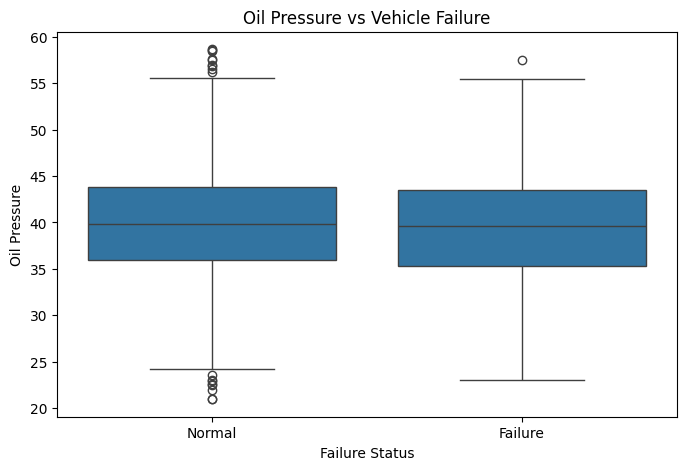

In [ ]:
# Oil pressure distribution by failure status

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='failure',
    y='oil_pressure',
    data=data
)

plt.title('Oil Pressure vs Vehicle Failure')
plt.xlabel('Failure Status')
plt.ylabel('Oil Pressure')

plt.xticks([0, 1], ['Normal', 'Failure'])

plt.show()

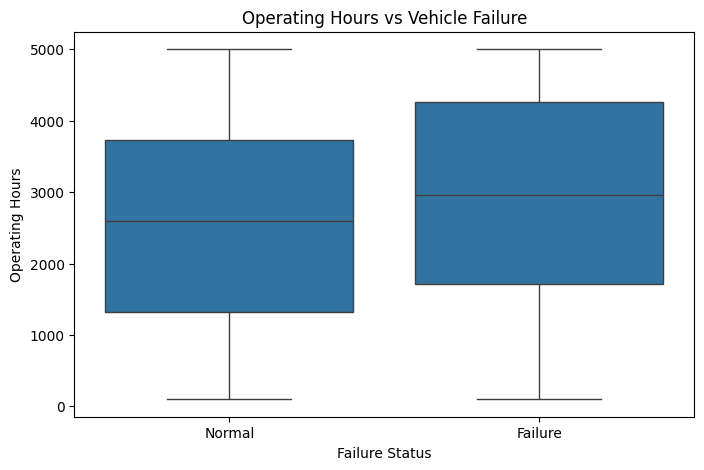

In [ ]:
# Operating hours distribution by failure status

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='failure',
    y='operating_hours',
    data=data
)

plt.title('Operating Hours vs Vehicle Failure')
plt.xlabel('Failure Status')
plt.ylabel('Operating Hours')

plt.xticks([0, 1], ['Normal', 'Failure'])

plt.show()

In [ ]:
# Define input features and target variable

features = [
    'engine_temperature',
    'rpm',
    'oil_pressure',
    'vibration',
    'battery_voltage',
    'coolant_temperature',
    'fuel_consumption',
    'vehicle_speed',
    'operating_hours'
]

X = data[features]
y = data['failure']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2000, 9)
Target shape: (2000,)


In [ ]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1600
Testing samples: 400


In [ ]:
# Create and train the Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
# Predict vehicle failure on the test dataset

y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [ ]:
# Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

Random Forest Accuracy: 83.25%


In [ ]:
# Generate classification report

print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.99      0.91       334
           1       0.33      0.02      0.03        66

    accuracy                           0.83       400
   macro avg       0.58      0.50      0.47       400
weighted avg       0.75      0.83      0.76       400



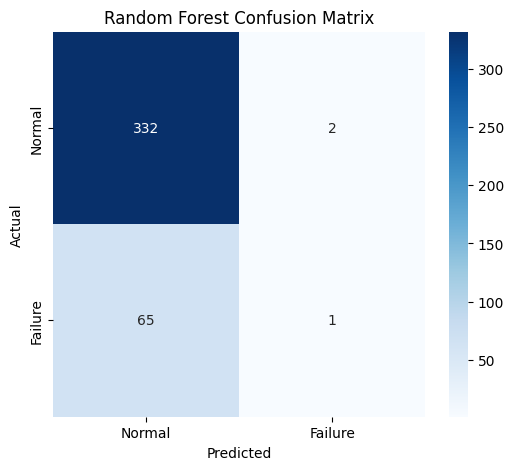

In [ ]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Failure'],
    yticklabels=['Normal', 'Failure']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [ ]:
# Calculate feature importance

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
8,operating_hours,0.125540
3,vibration,0.124925
2,oil_pressure,0.122957
0,engine_temperature,0.113329
5,coolant_temperature,0.106292
4,battery_voltage,0.106190
1,rpm,0.102974
7,vehicle_speed,0.099686
6,fuel_consumption,0.098106


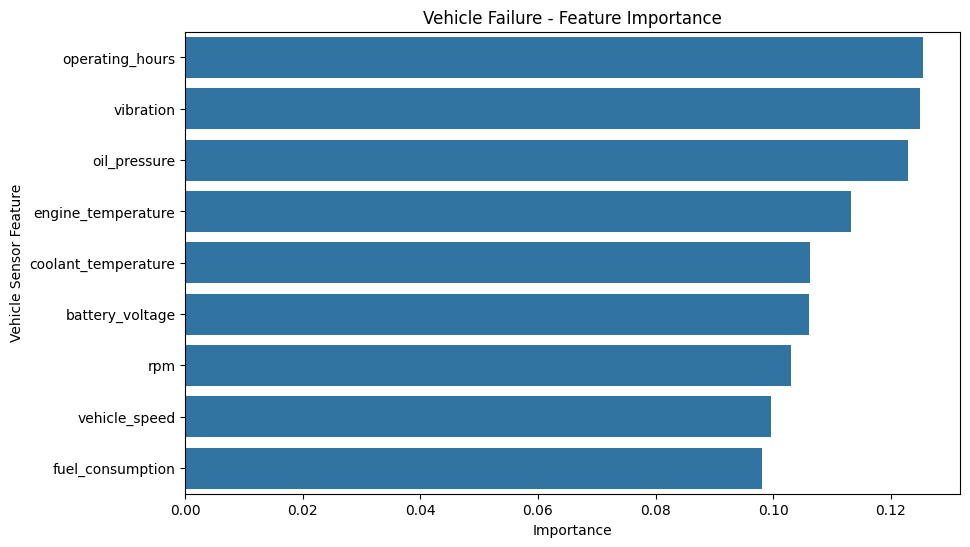

In [ ]:
# Visualize feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance
)

plt.title('Vehicle Failure - Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Vehicle Sensor Feature')

plt.show()

In [ ]:
# Generate failure probability for test vehicles

failure_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Failure probabilities generated successfully!")
print(failure_probabilities[:10])

Failure probabilities generated successfully!
[0.2  0.05 0.25 0.07 0.33 0.22 0.12 0.07 0.2  0.24]


In [ ]:
# Convert failure probability to percentage

failure_probability_percent = failure_probabilities * 100

print("First 10 Failure Probabilities:")
print(np.round(failure_probability_percent[:10], 2))

First 10 Failure Probabilities:
[20.  5. 25.  7. 33. 22. 12.  7. 20. 24.]


In [ ]:
# Calculate vehicle health score

vehicle_health_score = 100 - failure_probability_percent

print("First 10 Vehicle Health Scores:")
print(np.round(vehicle_health_score[:10], 2))

First 10 Vehicle Health Scores:
[80. 95. 75. 93. 67. 78. 88. 93. 80. 76.]


In [ ]:
# Create vehicle monitoring results

monitoring_results = X_test.copy()

monitoring_results['Actual_Failure'] = y_test.values
monitoring_results['Predicted_Failure'] = y_pred
monitoring_results['Failure_Probability'] = failure_probability_percent
monitoring_results['Vehicle_Health_Score'] = vehicle_health_score

monitoring_results.head(10)

,engine_temperature,rpm,oil_pressure,vibration,battery_voltage,coolant_temperature,fuel_consumption,vehicle_speed,operating_hours,Actual_Failure,Predicted_Failure,Failure_Probability,Vehicle_Health_Score
926,79.410782,2441.885478,37.308743,1.510546,11.824355,73.829845,9.020010,67.913522,4537.364465,1,0,20.0,80.0
315,85.210038,2710.793305,46.035547,1.858170,12.884568,87.323224,8.129820,57.773559,816.157943,0,0,5.0,95.0
1247,77.300268,2133.421901,30.647278,1.507514,12.004454,79.228923,6.746842,40.127080,4105.502621,0,0,25.0,75.0
1915,79.573262,2454.077618,34.638909,1.501116,12.644956,82.076765,6.400455,67.674076,1465.067347,0,0,7.0,93.0
334,94.751197,2945.191582,42.838230,1.442720,13.015690,81.600270,3.466122,45.973757,4661.767280,0,0,33.0,67.0
769,103.124486,2401.766708,44.780212,1.185394,12.889914,96.051269,7.172860,47.770333,2405.026033,0,0,22.0,78.0
1949,84.486063,1860.484632,31.031463,1.504429,13.150313,70.393448,7.853155,87.882040,1455.167581,0,0,12.0,88.0
116,84.652882,2385.700042,38.543808,1.911175,11.992918,83.556736,7.254540,68.154812,3561.258129,1,0,7.0,93.0
1779,78.075790,2456.965154,44.187844,1.029992,12.684249,73.261634,7.260735,71.366322,4315.731403,1,0,20.0,80.0
499,71.172003,2670.025647,32.834864,1.320960,13.032085,81.083931,5.263431,70.141555,3932.755917,0,0,24.0,76.0


In [ ]:
# Define vehicle health status

def health_status(score):
    if score >= 75:
        return 'NORMAL'
    elif score >= 50:
        return 'WARNING'
    else:
        return 'CRITICAL'

monitoring_results['Status'] = monitoring_results[
    'Vehicle_Health_Score'
].apply(health_status)

monitoring_results.head(10)

,engine_temperature,rpm,oil_pressure,vibration,battery_voltage,coolant_temperature,fuel_consumption,vehicle_speed,operating_hours,Actual_Failure,Predicted_Failure,Failure_Probability,Vehicle_Health_Score,Status
926,79.410782,2441.885478,37.308743,1.510546,11.824355,73.829845,9.020010,67.913522,4537.364465,1,0,20.0,80.0,NORMAL
315,85.210038,2710.793305,46.035547,1.858170,12.884568,87.323224,8.129820,57.773559,816.157943,0,0,5.0,95.0,NORMAL
1247,77.300268,2133.421901,30.647278,1.507514,12.004454,79.228923,6.746842,40.127080,4105.502621,0,0,25.0,75.0,NORMAL
1915,79.573262,2454.077618,34.638909,1.501116,12.644956,82.076765,6.400455,67.674076,1465.067347,0,0,7.0,93.0,NORMAL
334,94.751197,2945.191582,42.838230,1.442720,13.015690,81.600270,3.466122,45.973757,4661.767280,0,0,33.0,67.0,WARNING
769,103.124486,2401.766708,44.780212,1.185394,12.889914,96.051269,7.172860,47.770333,2405.026033,0,0,22.0,78.0,NORMAL
1949,84.486063,1860.484632,31.031463,1.504429,13.150313,70.393448,7.853155,87.882040,1455.167581,0,0,12.0,88.0,NORMAL
116,84.652882,2385.700042,38.543808,1.911175,11.992918,83.556736,7.254540,68.154812,3561.258129,1,0,7.0,93.0,NORMAL
1779,78.075790,2456.965154,44.187844,1.029992,12.684249,73.261634,7.260735,71.366322,4315.731403,1,0,20.0,80.0,NORMAL
499,71.172003,2670.025647,32.834864,1.320960,13.032085,81.083931,5.263431,70.141555,3932.755917,0,0,24.0,76.0,NORMAL


In [ ]:
# Count vehicles by health status

status_counts = monitoring_results['Status'].value_counts()

print(status_counts)

Status
NORMAL      317
WARNING      80
CRITICAL      3
Name: count, dtype: int64


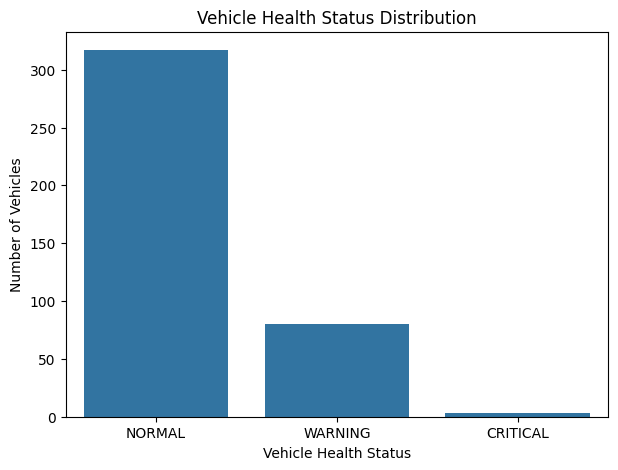

In [ ]:
# Visualize vehicle health status

plt.figure(figsize=(7, 5))

sns.countplot(
    x='Status',
    data=monitoring_results,
    order=['NORMAL', 'WARNING', 'CRITICAL']
)

plt.title('Vehicle Health Status Distribution')
plt.xlabel('Vehicle Health Status')
plt.ylabel('Number of Vehicles')

plt.show()

In [ ]:
# Generate maintenance recommendations

def maintenance_recommendation(status):
    if status == 'NORMAL':
        return 'No immediate maintenance required'
    elif status == 'WARNING':
        return 'Inspection recommended soon'
    else:
        return 'Immediate maintenance required'

monitoring_results['Maintenance_Alert'] = monitoring_results[
    'Status'
].apply(maintenance_recommendation)

monitoring_results.head(10)

,engine_temperature,rpm,oil_pressure,vibration,battery_voltage,coolant_temperature,fuel_consumption,vehicle_speed,operating_hours,Actual_Failure,Predicted_Failure,Failure_Probability,Vehicle_Health_Score,Status,Maintenance_Alert
926,79.410782,2441.885478,37.308743,1.510546,11.824355,73.829845,9.020010,67.913522,4537.364465,1,0,20.0,80.0,NORMAL,No immediate maintenance required
315,85.210038,2710.793305,46.035547,1.858170,12.884568,87.323224,8.129820,57.773559,816.157943,0,0,5.0,95.0,NORMAL,No immediate maintenance required
1247,77.300268,2133.421901,30.647278,1.507514,12.004454,79.228923,6.746842,40.127080,4105.502621,0,0,25.0,75.0,NORMAL,No immediate maintenance required
1915,79.573262,2454.077618,34.638909,1.501116,12.644956,82.076765,6.400455,67.674076,1465.067347,0,0,7.0,93.0,NORMAL,No immediate maintenance required
334,94.751197,2945.191582,42.838230,1.442720,13.015690,81.600270,3.466122,45.973757,4661.767280,0,0,33.0,67.0,WARNING,Inspection recommended soon
769,103.124486,2401.766708,44.780212,1.185394,12.889914,96.051269,7.172860,47.770333,2405.026033,0,0,22.0,78.0,NORMAL,No immediate maintenance required
1949,84.486063,1860.484632,31.031463,1.504429,13.150313,70.393448,7.853155,87.882040,1455.167581,0,0,12.0,88.0,NORMAL,No immediate maintenance required
116,84.652882,2385.700042,38.543808,1.911175,11.992918,83.556736,7.254540,68.154812,3561.258129,1,0,7.0,93.0,NORMAL,No immediate maintenance required
1779,78.075790,2456.965154,44.187844,1.029992,12.684249,73.261634,7.260735,71.366322,4315.731403,1,0,20.0,80.0,NORMAL,No immediate maintenance required
499,71.172003,2670.025647,32.834864,1.320960,13.032085,81.083931,5.263431,70.141555,3932.755917,0,0,24.0,76.0,NORMAL,No immediate maintenance required


In [ ]:
# Display the final vehicle monitoring results

final_columns = [
    'Failure_Probability',
    'Vehicle_Health_Score',
    'Status',
    'Maintenance_Alert'
]

monitoring_results[final_columns].head(15)

,Failure_Probability,Vehicle_Health_Score,Status,Maintenance_Alert
926,20.0,80.0,NORMAL,No immediate maintenance required
315,5.0,95.0,NORMAL,No immediate maintenance required
1247,25.0,75.0,NORMAL,No immediate maintenance required
1915,7.0,93.0,NORMAL,No immediate maintenance required
334,33.0,67.0,WARNING,Inspection recommended soon
769,22.0,78.0,NORMAL,No immediate maintenance required
1949,12.0,88.0,NORMAL,No immediate maintenance required
116,7.0,93.0,NORMAL,No immediate maintenance required
1779,20.0,80.0,NORMAL,No immediate maintenance required
499,24.0,76.0,NORMAL,No immediate maintenance required


In [ ]:
# Sort features according to their importance

top_features = feature_importance.head(5)

print("Top 5 Contributing Factors:\n")

for i, row in enumerate(top_features.itertuples(index=False), start=1):
    print(f"{i}. {row.Feature}: {row.Importance:.4f}")

Top 5 Contributing Factors:

1. operating_hours: 0.1255
2. vibration: 0.1249
3. oil_pressure: 0.1230
4. engine_temperature: 0.1133
5. coolant_temperature: 0.1063


In [ ]:
# Function for individual vehicle health prediction

def predict_vehicle_health(
    engine_temperature,
    rpm,
    oil_pressure,
    vibration,
    battery_voltage,
    coolant_temperature,
    fuel_consumption,
    vehicle_speed,
    operating_hours
):

    vehicle = pd.DataFrame([[
        engine_temperature,
        rpm,
        oil_pressure,
        vibration,
        battery_voltage,
        coolant_temperature,
        fuel_consumption,
        vehicle_speed,
        operating_hours
    ]], columns=features)

    # Predict failure probability
    failure_probability = rf_model.predict_proba(vehicle)[0][1] * 100

    # Calculate health score
    health_score = 100 - failure_probability

    # Determine status
    status = health_status(health_score)

    # Maintenance recommendation
    recommendation = maintenance_recommendation(status)

    return vehicle, failure_probability, health_score, status, recommendation

In [ ]:
# Example vehicle

vehicle, failure_probability, health_score, status, recommendation = predict_vehicle_health(
    engine_temperature=105,
    rpm=3200,
    oil_pressure=27,
    vibration=3.0,
    battery_voltage=11.2,
    coolant_temperature=102,
    fuel_consumption=10,
    vehicle_speed=65,
    operating_hours=4200
)

print("VEHICLE HEALTH MONITORING SYSTEM")
print("----------------------------------")
print(f"Failure Probability: {failure_probability:.2f}%")
print(f"Vehicle Health Score: {health_score:.2f}%")
print(f"Status: {status}")
print(f"Maintenance Alert: {recommendation}")

VEHICLE HEALTH MONITORING SYSTEM
----------------------------------
Failure Probability: 57.00%
Vehicle Health Score: 43.00%
Status: CRITICAL
Maintenance Alert: Immediate maintenance required


In [ ]:
# Identify abnormal sensor conditions

def identify_risk_factors(vehicle):

    risk_factors = []

    if vehicle['engine_temperature'].iloc[0] > 100:
        risk_factors.append("High engine temperature")

    if vehicle['vibration'].iloc[0] > 2.5:
        risk_factors.append("High vibration")

    if vehicle['oil_pressure'].iloc[0] < 30:
        risk_factors.append("Abnormal oil pressure")

    if vehicle['battery_voltage'].iloc[0] < 11.5:
        risk_factors.append("Low battery voltage")

    if vehicle['coolant_temperature'].iloc[0] > 100:
        risk_factors.append("High coolant temperature")

    if vehicle['operating_hours'].iloc[0] > 4000:
        risk_factors.append("High operating hours")

    return risk_factors

In [ ]:
# Display major contributing factors

risk_factors = identify_risk_factors(vehicle)

print("Major Contributing Factors:")

if risk_factors:
    for i, factor in enumerate(risk_factors, start=1):
        print(f"{i}. {factor}")
else:
    print("No major abnormal factors detected.")

Major Contributing Factors:
1. High engine temperature
2. High vibration
3. Abnormal oil pressure
4. Low battery voltage
5. High coolant temperature
6. High operating hours


In [ ]:
# Final vehicle health report

print("=" * 55)
print("       AI VEHICLE HEALTH MONITORING SYSTEM")
print("=" * 55)

print(f"\nVehicle Health Score   : {health_score:.2f}%")
print(f"Failure Probability   : {failure_probability:.2f}%")
print(f"Status                : {status}")

print("\nMajor Contributing Factors:")

if risk_factors:
    for i, factor in enumerate(risk_factors, start=1):
        print(f"{i}. {factor}")
else:
    print("No major abnormal factors detected.")

print(f"\nMaintenance Alert     : {recommendation}")

print("=" * 55)

       AI VEHICLE HEALTH MONITORING SYSTEM

Vehicle Health Score   : 43.00%
Failure Probability   : 57.00%
Status                : CRITICAL

Major Contributing Factors:
1. High engine temperature
2. High vibration
3. Abnormal oil pressure
4. Low battery voltage
5. High coolant temperature
6. High operating hours

Maintenance Alert     : Immediate maintenance required


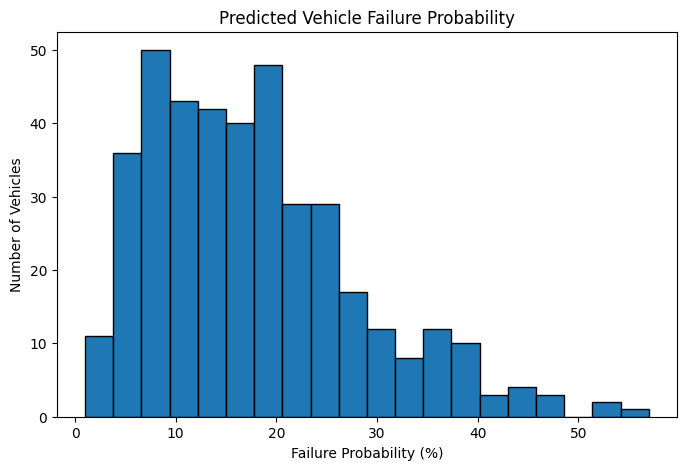

In [ ]:
# Distribution of predicted failure probabilities

plt.figure(figsize=(8, 5))

plt.hist(
    failure_probability_percent,
    bins=20,
    edgecolor='black'
)

plt.title('Predicted Vehicle Failure Probability')
plt.xlabel('Failure Probability (%)')
plt.ylabel('Number of Vehicles')

plt.show()

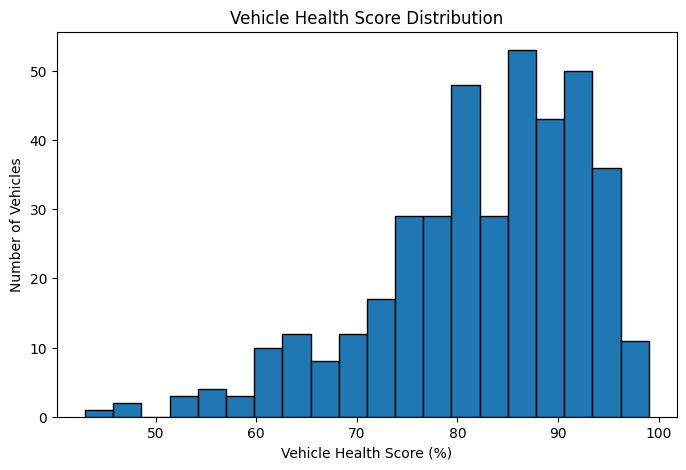

In [ ]:
# Distribution of vehicle health scores

plt.figure(figsize=(8, 5))

plt.hist(
    vehicle_health_score,
    bins=20,
    edgecolor='black'
)

plt.title('Vehicle Health Score Distribution')
plt.xlabel('Vehicle Health Score (%)')
plt.ylabel('Number of Vehicles')

plt.show()

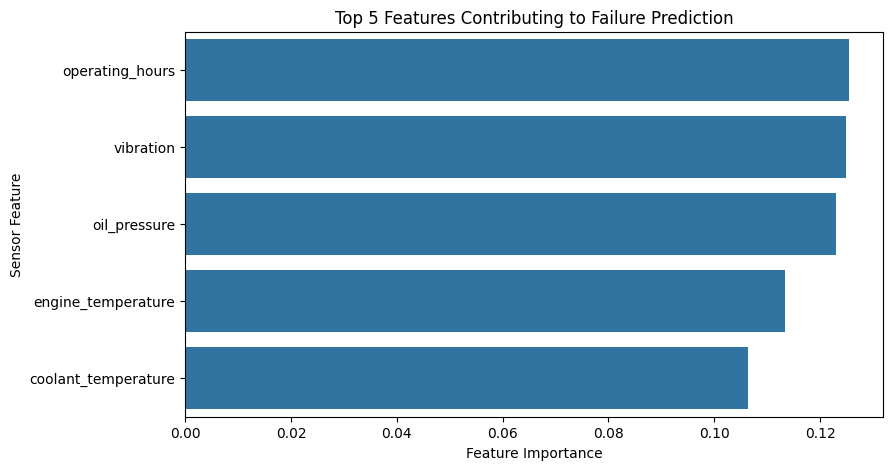

In [ ]:
# Top 5 features contributing to vehicle failure prediction

top_5_features = feature_importance.head(5)

plt.figure(figsize=(9, 5))

sns.barplot(
    x='Importance',
    y='Feature',
    data=top_5_features
)

plt.title('Top 5 Features Contributing to Failure Prediction')
plt.xlabel('Feature Importance')
plt.ylabel('Sensor Feature')

plt.show()

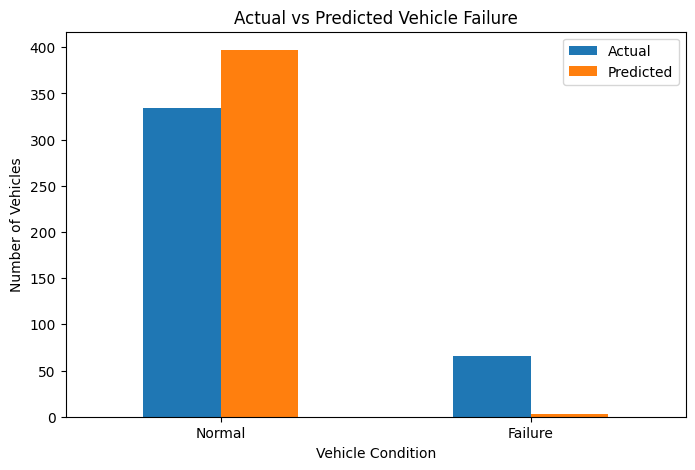

In [ ]:
# Compare actual and predicted failure counts

comparison = pd.DataFrame({
    'Actual': y_test.value_counts().sort_index(),
    'Predicted': pd.Series(y_pred).value_counts().sort_index()
})

comparison.index = ['Normal', 'Failure']

comparison.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Actual vs Predicted Vehicle Failure')
plt.xlabel('Vehicle Condition')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=0)

plt.show()

In [ ]:
# Save vehicle health monitoring results

monitoring_results.to_csv(
    'vehicle_health_monitoring_results.csv',
    index=False
)

print("Vehicle monitoring results saved successfully!")

Vehicle monitoring results saved successfully!


In [ ]:
# Save the complete vehicle sensor dataset

data.to_csv(
    'vehicle_predictive_maintenance_dataset.csv',
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
from google.colab import files

files.download('vehicle_predictive_maintenance_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('vehicle_health_monitoring_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Install XGBoost

!pip install -q xgboost

print("XGBoost installed successfully!")

XGBoost installed successfully!


In [ ]:
# Import XGBoost

from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [ ]:
# Create and train XGBoost model

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [ ]:
# Make predictions using XGBoost

xgb_pred = xgb_model.predict(X_test)

print("XGBoost predictions generated successfully!")

XGBoost predictions generated successfully!


In [ ]:
# Calculate XGBoost accuracy

xgb_accuracy = accuracy_score(y_test, xgb_pred)

print(f"XGBoost Accuracy: {xgb_accuracy * 100:.2f}%")

XGBoost Accuracy: 82.25%


In [ ]:
# XGBoost classification report

print("XGBoost Classification Report:\n")
print(classification_report(y_test, xgb_pred))

XGBoost Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.98      0.90       334
           1       0.27      0.05      0.08        66

    accuracy                           0.82       400
   macro avg       0.56      0.51      0.49       400
weighted avg       0.74      0.82      0.77       400



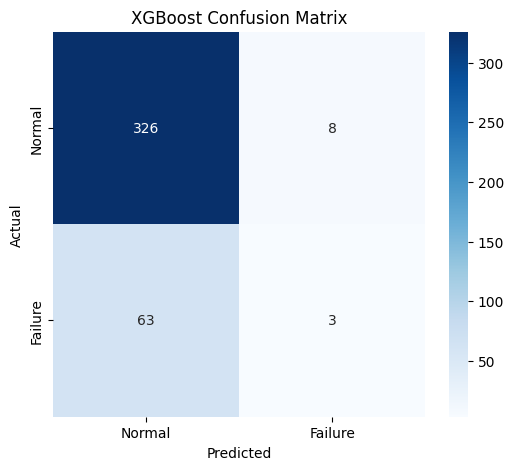

In [ ]:
# XGBoost confusion matrix

xgb_cm = confusion_matrix(y_test, xgb_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Failure'],
    yticklabels=['Normal', 'Failure']
)

plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [ ]:
# Compare model accuracy

model_comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy * 100,
        xgb_accuracy * 100
    ]
})

model_comparison

,Model,Accuracy
0,Random Forest,83.25
1,XGBoost,82.25


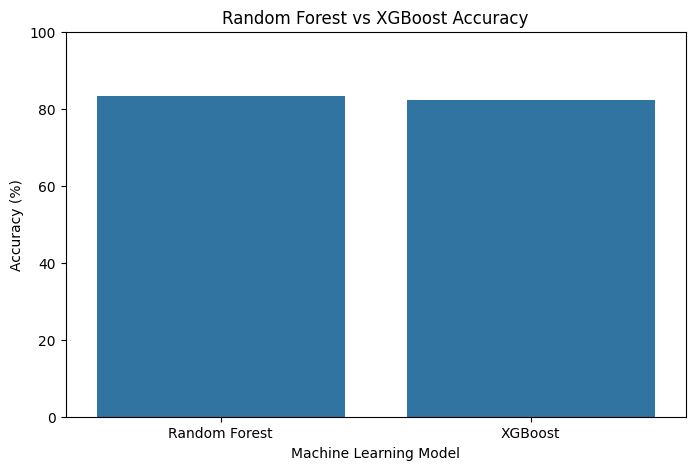

In [ ]:
# Visualize model accuracy comparison

plt.figure(figsize=(8, 5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=model_comparison
)

plt.title('Random Forest vs XGBoost Accuracy')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy (%)')

plt.ylim(0, 100)

plt.show()

In [ ]:
# XGBoost feature importance

xgb_importance = pd.DataFrame({
    'Feature': features,
    'Importance': xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
)

xgb_importance

,Feature,Importance
8,operating_hours,0.137719
2,oil_pressure,0.119895
3,vibration,0.119406
5,coolant_temperature,0.113041
1,rpm,0.105543
0,engine_temperature,0.104790
7,vehicle_speed,0.101629
4,battery_voltage,0.099214
6,fuel_consumption,0.098761


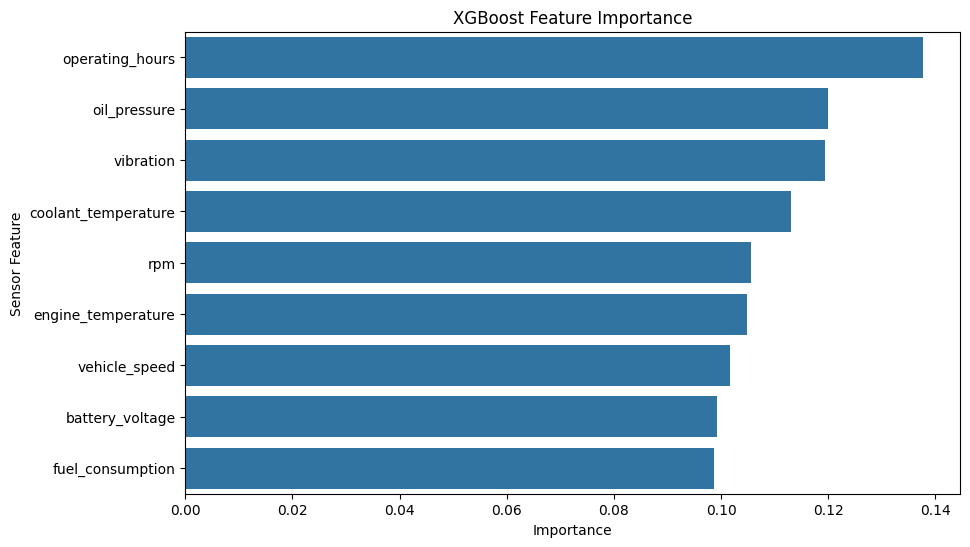

In [ ]:
# Visualize XGBoost feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=xgb_importance
)

plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Sensor Feature')

plt.show()

In [ ]:
# Interactive Vehicle Health Prediction System

print("ENTER VEHICLE SENSOR VALUES")
print("=" * 45)

engine_temperature = float(input("Engine Temperature (°C): "))
rpm = float(input("RPM: "))
oil_pressure = float(input("Oil Pressure: "))
vibration = float(input("Vibration Level: "))
battery_voltage = float(input("Battery Voltage (V): "))
coolant_temperature = float(input("Coolant Temperature (°C): "))
fuel_consumption = float(input("Fuel Consumption: "))
vehicle_speed = float(input("Vehicle Speed (km/h): "))
operating_hours = float(input("Operating Hours: "))

vehicle, failure_probability, health_score, status, recommendation = predict_vehicle_health(
    engine_temperature,
    rpm,
    oil_pressure,
    vibration,
    battery_voltage,
    coolant_temperature,
    fuel_consumption,
    vehicle_speed,
    operating_hours
)

risk_factors = identify_risk_factors(vehicle)

print("\n" + "=" * 55)
print("       VEHICLE HEALTH MONITORING RESULT")
print("=" * 55)

print(f"Vehicle Health Score : {health_score:.2f}%")
print(f"Failure Probability  : {failure_probability:.2f}%")
print(f"Status               : {status}")

print("\nMajor Contributing Factors:")

if risk_factors:
    for i, factor in enumerate(risk_factors, 1):
        print(f"{i}. {factor}")
else:
    print("No major abnormal factors detected.")

print(f"\nMaintenance Alert    : {recommendation}")

print("=" * 55)

ENTER VEHICLE SENSOR VALUES
Engine Temperature (°C): 105
RPM: 3200
Oil Pressure: 27
Vibration Level: 3.0
Battery Voltage (V): 11.2
Coolant Temperature (°C): 102
Fuel Consumption: 10
Vehicle Speed (km/h): 65
Operating Hours: 4200

       VEHICLE HEALTH MONITORING RESULT
Vehicle Health Score : 43.00%
Failure Probability  : 57.00%
Status               : CRITICAL

Major Contributing Factors:
1. High engine temperature
2. High vibration
3. Abnormal oil pressure
4. Low battery voltage
5. High coolant temperature
6. High operating hours

Maintenance Alert    : Immediate maintenance required


In [ ]:
# Normal vehicle example

normal_vehicle, normal_failure_probability, normal_health_score, normal_status, normal_recommendation = predict_vehicle_health(
    engine_temperature=82,
    rpm=2200,
    oil_pressure=43,
    vibration=1.0,
    battery_voltage=12.7,
    coolant_temperature=78,
    fuel_consumption=6,
    vehicle_speed=55,
    operating_hours=1200
)

normal_risk_factors = identify_risk_factors(normal_vehicle)

print("=" * 55)
print("          NORMAL VEHICLE EXAMPLE")
print("=" * 55)

print(f"Vehicle Health Score : {normal_health_score:.2f}%")
print(f"Failure Probability  : {normal_failure_probability:.2f}%")
print(f"Status               : {normal_status}")
print(f"Maintenance Alert    : {normal_recommendation}")

print("\nRisk Factors:")

if normal_risk_factors:
    for factor in normal_risk_factors:
        print("-", factor)
else:
    print("No major abnormal factors detected.")

print("=" * 55)

          NORMAL VEHICLE EXAMPLE
Vehicle Health Score : 83.00%
Failure Probability  : 17.00%
Status               : NORMAL
Maintenance Alert    : No immediate maintenance required

Risk Factors:
No major abnormal factors detected.


In [ ]:
# Critical vehicle example

critical_vehicle, critical_failure_probability, critical_health_score, critical_status, critical_recommendation = predict_vehicle_health(
    engine_temperature=115,
    rpm=4500,
    oil_pressure=22,
    vibration=3.8,
    battery_voltage=10.8,
    coolant_temperature=108,
    fuel_consumption=13,
    vehicle_speed=90,
    operating_hours=4800
)

critical_risk_factors = identify_risk_factors(critical_vehicle)

print("=" * 55)
print("          CRITICAL VEHICLE EXAMPLE")
print("=" * 55)

print(f"Vehicle Health Score : {critical_health_score:.2f}%")
print(f"Failure Probability  : {critical_failure_probability:.2f}%")
print(f"Status               : {critical_status}")

print("\nMajor Contributing Factors:")

if critical_risk_factors:
    for i, factor in enumerate(critical_risk_factors, 1):
        print(f"{i}. {factor}")

print(f"\nMaintenance Alert    : {critical_recommendation}")

print("=" * 55)

          CRITICAL VEHICLE EXAMPLE
Vehicle Health Score : 44.00%
Failure Probability  : 56.00%
Status               : CRITICAL

Major Contributing Factors:
1. High engine temperature
2. High vibration
3. Abnormal oil pressure
4. Low battery voltage
5. High coolant temperature
6. High operating hours

Maintenance Alert    : Immediate maintenance required


In [ ]:
# Final project summary

print("=" * 60)
print(" AI/ML-BASED PREDICTIVE MAINTENANCE SYSTEM")
print("=" * 60)

print("\nProject Features:")
print("✓ Automotive sensor data generation")
print("✓ Data preprocessing and validation")
print("✓ Exploratory Data Analysis")
print("✓ Random Forest failure prediction")
print("✓ XGBoost failure prediction")
print("✓ Model performance comparison")
print("✓ Failure probability estimation")
print("✓ Vehicle health score calculation")
print("✓ Vehicle health classification")
print("✓ Maintenance alert generation")
print("✓ Feature importance analysis")
print("✓ Individual vehicle diagnosis")

print("\nSensor Parameters Used:")
for feature in features:
    print("-", feature)

print("\nMachine Learning Models:")
print("- Random Forest")
print("- XGBoost")

print("\nHealth Status Categories:")
print("- NORMAL")
print("- WARNING")
print("- CRITICAL")

print("\nProject completed successfully!")
print("=" * 60)

 AI/ML-BASED PREDICTIVE MAINTENANCE SYSTEM

Project Features:
✓ Automotive sensor data generation
✓ Data preprocessing and validation
✓ Exploratory Data Analysis
✓ Random Forest failure prediction
✓ XGBoost failure prediction
✓ Model performance comparison
✓ Failure probability estimation
✓ Vehicle health score calculation
✓ Vehicle health classification
✓ Maintenance alert generation
✓ Feature importance analysis
✓ Individual vehicle diagnosis

Sensor Parameters Used:
- engine_temperature
- rpm
- oil_pressure
- vibration
- battery_voltage
- coolant_temperature
- fuel_consumption
- vehicle_speed
- operating_hours

Machine Learning Models:
- Random Forest
- XGBoost

Health Status Categories:
- NORMAL
- WARNING
- CRITICAL

Project completed successfully!


In [ ]:
# Store model performance

performance = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy (%)': [
        accuracy * 100,
        xgb_accuracy * 100
    ]
})

performance

,Model,Accuracy (%)
0,Random Forest,83.25
1,XGBoost,82.25


In [ ]:
# Save model comparison results

performance.to_csv(
    'model_performance_comparison.csv',
    index=False
)

print("Model performance saved successfully!")

Model performance saved successfully!


In [ ]:
# Save Random Forest feature importance

feature_importance.to_csv(
    'random_forest_feature_importance.csv',
    index=False
)

# Save XGBoost feature importance

xgb_importance.to_csv(
    'xgboost_feature_importance.csv',
    index=False
)

print("Feature importance files saved successfully!")

Feature importance files saved successfully!


In [ ]:
# Final project results

print("FINAL MODEL PERFORMANCE")
print("=" * 40)

print(f"Random Forest Accuracy : {accuracy * 100:.2f}%")
print(f"XGBoost Accuracy       : {xgb_accuracy * 100:.2f}%")

print("\nDataset Information")
print("-" * 40)
print(f"Total observations     : {len(data)}")
print(f"Number of features     : {len(features)}")
print(f"Training observations  : {len(X_train)}")
print(f"Testing observations   : {len(X_test)}")

print("\nProject Status")
print("-" * 40)
print("Predictive maintenance system completed.")

FINAL MODEL PERFORMANCE
Random Forest Accuracy : 83.25%
XGBoost Accuracy       : 82.25%

Dataset Information
----------------------------------------
Total observations     : 2000
Number of features     : 9
Training observations  : 1600
Testing observations   : 400

Project Status
----------------------------------------
Predictive maintenance system completed.


In [ ]:
from google.colab import files

files.download('vehicle_predictive_maintenance_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('vehicle_health_monitoring_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('model_performance_comparison.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('random_forest_feature_importance.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('xgboost_feature_importance.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>